# Li Han Lin, e1123147: final model for the BT4012 fraud detection competition

Rebuilds my two final submissions from the raw competition files:

- **Final 1** (top submission, public AUROC 0.96823): main model + 25% of a labelled-only CatBoost
- **Final 2** (public AUROC 0.96734): 50/50 hedge between the main model and the labelled-only CatBoost + LightGBM

Sections (after the key decisions below):
1. Setup and settings
2. Data loading and preprocessing
3. Hyperparameter tuning (Optuna)
4. Feature engineering: two-stage graph features
5. Validation
6. Final models and submission files

Full run: about 40 min on 4 CPU threads. Turning on the Optuna re-run (section 3) adds about 20 min.

## Key decisions

A short summary of how I got to this model, before the details. Scores are public ROC AUC unless I say "locally".

**Validation.** The test periods (36–49) come after every training period, so I only validated forward in time: train on earlier periods, score later ones. A random split leaks the future and gives about 0.999 for every model, which tells you nothing. Several times the local windows and the leaderboard disagreed: the local windows ranked tau the opposite way round, and liked the anomaly features that lost on public. In those cases the public leaderboard decided, since it is a random sample of the actual test periods. Section 5 shows the windows I used, and section 2 shows why there are three.

**Model family.** Tuned CatBoost was the strongest single model (0.94944). LightGBM scored 0.94606, random forest 0.932, and logistic regression, neural nets and a graph neural network were all clearly weaker locally. Later, LightGBM came back as a second model: alone it was as good as CatBoost (0.96000 vs 0.96009), but it made different mistakes, so a 50/50 blend of the two did better (0.96168). XGBoost as a third model made things worse (0.96760).

**Using the graph.** The neighbour-score stage gave the first real jump (0.94983 → 0.95252): each transaction gets features from its labelled neighbours' first-stage fraud scores. Raw neighbour feature averages, degrees and paths, a GNN, and 2-hop scores through unlabelled nodes (0.96134) didn't add anything. I only count *labelled* neighbours. Unlabelled transactions in the test periods have no features, so this keeps training and test looking the same.

**Time drift.** Weighting recent periods more, `exp((t − 35) / 10)`, gave the next jump (0.95252 → 0.96009). Tau 10 beat 7, 20 and 30. Two-piece versions with a different tau before and after period 24 scored lower (0.95995–0.96110), and "learned" weights based on how test-like a row looks were much worse locally.

**Unlabelled rows.** The biggest single gain came from not throwing away the 78% of training rows without a label. I treat them as licit at 0.3× weight: 0 → 0.96168, 0.15 → 0.96759, **0.3 → 0.96816**, 0.6 → 0.96763, 1 → 0.967. Full weight is worse because some of them are fraud that was never labelled.

**Hyperparameters.** CatBoost and LightGBM were tuned with Optuna on forward folds (section 3). Shallower or more regularised versions always lost on the leaderboard (0.94780, and 0.94360 for a bag of shallow models), so I kept the tuned capacity.

**What I left out.** PCA: a model on 30 PCA components was about 0.06 AUC worse locally, and adding the components to stage 2 scored 0.95967. Trees already cope with the 165 correlated features, and PCA keeps the directions with the most variance, not the ones that separate fraud. Weight of evidence encoding helped logistic regression but hurt the trees (0.950 vs 0.961 locally). IsolationForest anomaly scores looked great locally but lost on public (0.95997 / 0.96080). Dropping the local or the aggregated feature group cost 0.03–0.04 locally.

**Final picks.** Final 1 is the best public score (0.96823): the main model plus 25% of a labelled-only CatBoost. For final 2 I didn't pick another near-copy of final 1. I took a 50/50 hedge with the labelled-only CatBoost + LightGBM (0.96734). On the harder validation windows the unknowns-based model drops a lot, while the labelled-only one holds up (section 5). If the private leaderboard behaves more like those windows, the hedge protects me, and on public it only costs 0.0009.

Overall, what helped either added information the test set also has (neighbour scores, the unlabelled rows, a second model type) or matched training to the test periods (recency). What lost mostly threw information or capacity away.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import catboost, lightgbm
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

from utils import load_data, rank_pct, as_written, save_submission

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

RUN_TUNING = False      # True = rerun both Optuna searches (~20 min)
RUN_VALIDATION = True   # False = skip section 5 (~15 min)

T0 = time.time()
print('catboost', catboost.__version__, '| lightgbm', lightgbm.__version__, '| pandas', pd.__version__)

catboost 1.2.8 | lightgbm 4.7.0 | pandas 3.0.6


Imports, paths and two switches. The data is expected in `data/`, and outputs go to `outputs/`. `utils.py` only holds plumbing (reading the CSVs, rank helpers, saving files); every modelling step is in this notebook. The tuning re-run is off by default: the searches were already run once, and their trial logs are loaded in section 3. The versions are printed because the results are reproducible byte for byte only with the versions in `requirements.txt`.

In [2]:
FEATURES = [f'feat_{i}' for i in range(1, 166)]
LAST_TRAIN_PERIOD = 35

# recency: a row from period t gets weight exp((t - 35) / TAU).
# tried 7 / 10 / 20 / 30 on the leaderboard -> 0.95809 / 0.96009 / 0.95698 / 0.95722, so 10
TAU = 10.0

# unknown-label rows are used as licit (0) but only count this much.
# tried 0 / 0.15 / 0.3 / 0.6 / 1 -> 0.96168 / 0.96759 / 0.96816 / 0.96763 / 0.967, so 0.3
UNKNOWN_WEIGHT = 0.3

# final 1: share of the labelled-only CatBoost blended into the main model (0 -> 0.96816, 0.25 -> 0.96823)
OLD_VIEW_SHARE = 0.25
# final 2: 50/50 between the main model and the labelled-only CatBoost + LightGBM (0.96734)
HEDGE_SHARE = 0.5

# stage 1 is averaged over 3 seeds, stage 2 over 5
SEEDS = dict(stage1=(42, 137, 2026), stage2=(42, 137, 2026, 7, 99))

These are the three settings of the final recipe. Each was picked on the public leaderboard, changing one thing at a time; the comments list the scores tried. They were not picked on local validation, because the local windows ranked tau the wrong way round (see section 5).

- `TAU`: test periods come after all training periods, and the features drift, so recent rows should count more. Weight halves about every 7 periods.
- `UNKNOWN_WEIGHT`: 78% of training rows have no label. Treating them as licit adds a lot of "normal" examples. They only get 0.3 weight because some of them are fraud that was never labelled.
- `OLD_VIEW_SHARE` / `HEDGE_SHARE`: how much of the models that never saw the unknowns goes into each final. Final 1 takes a small share of the labelled-only CatBoost. Final 2 is an even split with the labelled-only CatBoost + LightGBM, a bigger hedge in case the unknowns mislead on part of the test set (see section 5).
- `SEEDS`: averaging a few seeds reduces random noise in the scores.

## 2. Data loading and preprocessing

In [3]:
train, test, edges = load_data(DATA)

print(train.shape, test.shape, edges.shape)
print(train.label.map({1: 'illicit', 0: 'licit'}).fillna('unknown').value_counts())

(141772, 168) (15329, 168) (234355, 2)
label
unknown    110537
licit       27591
illicit      3644
Name: count, dtype: int64


`train.csv` covers periods 1–35, `test.csv` covers periods 36–49, and the edge list holds the graph (txId1 → txId2 = money flows from txId1 to txId2). `load_data` reads the features as float32; all my submissions used that, and float64 changes the last digits of the predictions.

Only 3,644 of 141,772 training rows are labelled illicit and 27,591 licit. The other 110,537 have no label.

In [4]:
def training_frame(df, use_unknowns):
    if use_unknowns:
        t = df.copy()
        unknown = t.label.isna().values
        t['label'] = t.label.fillna(0).astype(int)     # unknown -> licit
    else:
        t = df[df.label.notna()].copy()                # labelled rows only
        t['label'] = t.label.astype(int)
        unknown = np.zeros(len(t), dtype=bool)
    return t, unknown


def row_weights(time_step, unknown, cutoff):
    return np.exp((time_step - cutoff) / TAU) * np.where(unknown, UNKNOWN_WEIGHT, 1.0)


w = row_weights(np.arange(1, 36), np.zeros(35, bool), LAST_TRAIN_PERIOD)
print('weight at period 1 / 15 / 25 / 35:', w[[0, 14, 24, 34]].round(3))

weight at period 1 / 15 / 25 / 35: [0.033 0.135 0.368 1.   ]


These are the two preprocessing steps.

`training_frame` builds the training table in one of two ways. With the unknowns, every row is kept and missing labels become 0. Without them, only labelled rows are kept, which is what I did for most of the project. The main model uses the first; the "old view" CatBoost uses the second.

`row_weights` gives each training row its weight: the recency part times 0.3 for unknown rows. As printed, period 25 counts about a third as much as period 35, and period 1 about 3%. Old data still counts, just much less.

### Fraud over time: does the fraud stay the same?

The test periods (36–49) come after all training periods. So the key question is whether fraud in later periods looks like fraud the model has already seen. Two quick checks, on labelled rows only and using LightGBM with its tuned settings (no recency or graph features):

1. **Frozen models:** train once on periods ≤ 17, ≤ 21 or ≤ 28, then score every later period separately.
2. **Novelty:** for the fraud in each period, how far is it (standardised features) from the nearest fraud in any *earlier* period?

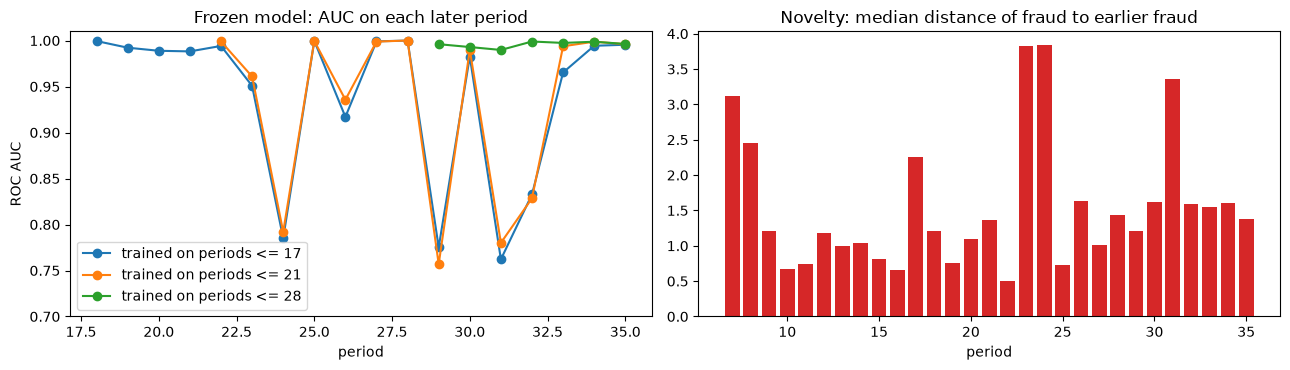

frozen <= 21: {24: 0.792, 29: 0.757, 31: 0.78, 32: 0.829}


In [5]:
import json
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

lab = train[train.label.notna()].copy()
lab['label'] = lab.label.astype(int)
eda_params = dict(json.load(open(ROOT / 'tuning/lightgbm_best_trial.json'))['params'], subsample_freq=1)

frozen = {}
for c in (17, 21, 28):
    past = lab[lab.time_step <= c]
    m = LGBMClassifier(random_state=42, n_jobs=4, verbose=-1, **eda_params).fit(past[FEATURES], past.label)
    frozen[c] = {p: roc_auc_score(g.label, m.predict_proba(g[FEATURES])[:, 1])
                 for p, g in lab[lab.time_step > c].groupby('time_step') if g.label.nunique() == 2}

X = StandardScaler().fit_transform(lab[FEATURES])
ill, ts = lab.label.values == 1, lab.time_step.values
novelty = {}
for p in range(7, 36):
    nn = NearestNeighbors(n_neighbors=1).fit(X[ill & (ts < p)])
    novelty[p] = float(np.median(nn.kneighbors(X[ill & (ts == p)])[0]))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for c, auc in frozen.items():
    ax[0].plot(list(auc), list(auc.values()), marker='o', label=f'trained on periods <= {c}')
ax[0].set(title='Frozen model: AUC on each later period', xlabel='period', ylabel='ROC AUC', ylim=(0.7, 1.01)); ax[0].legend()
ax[1].bar(list(novelty), list(novelty.values()), color='#d62728')
ax[1].set(title='Novelty: median distance of fraud to earlier fraud', xlabel='period')
plt.tight_layout(); plt.show()
print('frozen <= 21:', {p: round(a, 3) for p, a in frozen[21].items() if a < 0.9})

Most periods are easy (AUC about 0.99) even for a model trained long before. But the models frozen at 17 and 21 **break down on specific periods: 24, 29, 31 and 32** (AUC about 0.76–0.83). The novelty bars point the same way: fraud in periods 23–24 and 31 sits much further from all earlier fraud than usual. So new kinds of fraud appear at those points. Once they're in the training data, they're caught: the model trained on periods ≤ 28 scores 0.99+ on every period from 29 to 35.

This is why section 5 doesn't rely on one validation window:
- **≤ 28 → 29–35** contains only fraud the model has already seen, so every reasonable model scores about 0.998 there and it can't separate ideas.
- **≤ 17 → 18–31** and **≤ 21 → 22–35** contain the new fraud types at 24, 29 and 31, which is the hard part of the real task. Each looks 14 periods ahead, the same distance as the real test (36–49).

The test periods (36–49) come later still, so they may well contain new patterns of their own.

## 3. Hyperparameter tuning (Optuna)

In [6]:
DEV_FOLDS = [(14, 15, 21), (21, 22, 28)]   # (train up to, validate from, validate to)

def dev_split(end, start, stop):
    lab = train[train.label.notna()].copy()
    lab['label'] = lab.label.astype(int)
    return lab[lab.time_step <= end], lab[lab.time_step.between(start, stop)]


def catboost_space(trial):
    return dict(iterations=trial.suggest_int('iterations', 100, 500, step=50),
                depth=trial.suggest_int('depth', 4, 7),
                learning_rate=trial.suggest_float('learning_rate', 0.02, 0.085, log=True),
                l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 0.5, 10.0, log=True),
                random_strength=trial.suggest_float('random_strength', 0.001, 0.2, log=True),
                subsample=trial.suggest_float('subsample', 0.8, 1.0),
                rsm=trial.suggest_float('rsm', 0.65, 0.9),
                auto_class_weights='Balanced', boosting_type='Ordered')


def lightgbm_space(trial):
    return dict(n_estimators=trial.suggest_int('n_estimators', 200, 1000, step=100),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                num_leaves=trial.suggest_categorical('num_leaves', [15, 31, 63]),
                min_child_samples=trial.suggest_int('min_child_samples', 20, 150),
                colsample_bytree=trial.suggest_float('colsample_bytree', 0.65, 1.0),
                subsample=trial.suggest_float('subsample', 0.65, 1.0),
                reg_alpha=trial.suggest_float('reg_alpha', 1e-8, 5.0, log=True),
                reg_lambda=trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
                class_weight=trial.suggest_categorical('class_weight', [None, 'balanced']))


def objective(kind):
    def f(trial):
        if kind == 'catboost':
            model = lambda: CatBoostClassifier(random_seed=42, thread_count=4, verbose=False, allow_writing_files=False,
                                               bootstrap_type='Bernoulli', **catboost_space(trial))
        else:
            p = lightgbm_space(trial)
            model = lambda: LGBMClassifier(random_state=42, n_jobs=4, verbose=-1, subsample_freq=1, **p)
        aucs = []
        for end, start, stop in DEV_FOLDS:
            tr_, va_ = dev_split(end, start, stop)
            aucs.append(roc_auc_score(va_.label, model().fit(tr_[FEATURES], tr_.label).predict_proba(va_[FEATURES])[:, 1]))
        return float(np.mean(aucs))
    return f


if RUN_TUNING:
    import optuna
    for kind, n in [('catboost', 30), ('lightgbm', 25)]:
        study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(objective(kind), n_trials=n)
        print(kind, round(study.best_value, 4), study.best_params)

cb_trials = pd.read_csv(ROOT / 'tuning/catboost_optuna_trials.csv')
lgb_trials = pd.read_csv(ROOT / 'tuning/lightgbm_optuna_trials.csv')
for name, t in [('CatBoost', cb_trials), ('LightGBM', lgb_trials)]:
    print(f"{name}: {len(t)} trials, best mean AUC {t.value.max():.4f} (trial {t.loc[t.value.idxmax(), 'number']}), "
          f"first trial {t.value.iloc[0]:.4f}")
cb_trials.sort_values('value', ascending=False).head(5).filter(regex='number|value|params_')

CatBoost: 30 trials, best mean AUC 0.9807 (trial 29), first trial 0.9791
LightGBM: 25 trials, best mean AUC 0.9761 (trial 18), first trial 0.9604


,number,value,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_random_strength,params_rsm,params_subsample
29,29,0.980728,6,300,5.471638,0.067086,0.002158,0.696772,0.993821
22,22,0.980187,5,250,5.297672,0.052725,0.004015,0.782198,0.991349
18,18,0.980108,6,300,3.907567,0.069532,0.003809,0.721620,0.971609
21,21,0.979683,5,250,5.320452,0.055867,0.006709,0.765901,0.982868
26,26,0.979672,5,300,7.739391,0.056295,0.002248,0.740261,0.952801


This is where the CatBoost and LightGBM parameters come from. Each search used Optuna (TPE sampler, seed 42) on the **labelled rows only**, scored on two forward folds: train on periods ≤ 14 and score 15–21, then train on ≤ 21 and score 22–28. The objective is the mean ROC AUC of the two folds. The folds are forward in time on purpose, to mimic predicting future periods.

- CatBoost: 30 trials, best mean AUC 0.9807 (trial 29). Depth, tree count, learning rate, regularisation and sampling were searched. Class weights stayed `Balanced` and boosting `Ordered`, which worked best in an earlier, wider search.
- LightGBM: 25 trials, best mean AUC 0.9761 (trial 18).

The searches ran once, before I added the graph stage, the recency weights and the unknowns. The tables loaded here are their saved trial logs. Setting `RUN_TUNING = True` reruns both searches with the same spaces and folds. The trial order may not match the log exactly (different Optuna / library builds), but the best settings land in the same region.

In [7]:
import json
best_cb = json.load(open(ROOT / 'tuning/catboost_best_trial.json'))
best_lgb = json.load(open(ROOT / 'tuning/lightgbm_best_trial.json'))

# the trial logs above store parameters rounded, so take the exact values from the saved best trials
for best, log in [(best_cb, cb_trials), (best_lgb, lgb_trials)]:
    row = log.loc[log.number == best['number']].iloc[0]
    assert np.isclose(row.value, best['mean_fold_roc_auc'])
    assert all(np.isclose(row['params_' + k], v) if isinstance(v, float) else True for k, v in best['params'].items())

CATBOOST_PARAMS = dict(**best_cb['params'], loss_function='Logloss', bootstrap_type='Bernoulli',
                       thread_count=4, verbose=False, allow_writing_files=False)
LIGHTGBM_PARAMS = dict(**best_lgb['params'], subsample_freq=1)
print(CATBOOST_PARAMS); print(LIGHTGBM_PARAMS)

{'iterations': 300, 'depth': 6, 'learning_rate': 0.06708626081653052, 'l2_leaf_reg': 5.47163796093696, 'random_strength': 0.00215820240737873, 'subsample': 0.9938211640004143, 'rsm': 0.6967719144484393, 'auto_class_weights': 'Balanced', 'boosting_type': 'Ordered', 'loss_function': 'Logloss', 'bootstrap_type': 'Bernoulli', 'thread_count': 4, 'verbose': False, 'allow_writing_files': False}
{'class_weight': 'balanced', 'colsample_bytree': 0.7281598757483032, 'learning_rate': 0.023472044428273456, 'min_child_samples': 113, 'n_estimators': 300, 'num_leaves': 31, 'reg_alpha': 0.004742424030646645, 'reg_lambda': 0.031223163016173654, 'subsample': 0.8974893946313489, 'subsample_freq': 1}


The model parameters come from the best trial of each search (CatBoost trial 29, LightGBM trial 18), saved with full precision in `tuning/*_best_trial.json`, not typed in by hand. The trial logs round some values to 15–16 digits, which is enough to change CatBoost's output slightly. So the exact values come from the JSON, and the asserts check they match the log. `subsample_freq=1` is needed for LightGBM's row subsampling to take effect at all, and the search used it too. The fixed CatBoost settings (Logloss, Bernoulli bootstrap, 4 threads) match the search.

## 4. Feature engineering: two-stage graph features

In [8]:
# every edge seen from both ends. for node a and neighbour b:
# d='out' if a -> b (b receives from a), d='in' if b -> a (b sends to a)
und = pd.concat([edges.rename(columns={'txId1': 'a', 'txId2': 'b'}).assign(d='out'),
                 edges.rename(columns={'txId2': 'a', 'txId1': 'b'}).assign(d='in')])

lab_ids = train.loc[train.label.notna()].set_index('txId').label
pairs = und[und.a.isin(lab_ids.index) & und.b.isin(lab_ids.index)]
nbr_illicit = pairs.b.map(lab_ids).groupby(pairs.a.map(lab_ids)).mean()
print(f'share of illicit neighbours: licit node {nbr_illicit[0]:.3f}, illicit node {nbr_illicit[1]:.3f}')

share of illicit neighbours: licit node 0.028, illicit node 0.574


This is the motivation for the graph features. Among labelled transactions, an illicit one has a far higher share of illicit neighbours than a licit one (printed above). So a transaction's neighbours tell us something about it. The edge list is turned into an "undirected with direction tag" table, so each node can look up both its senders (`in`) and its receivers (`out`).

In [9]:
def nbr_feats(score):
    # max / mean / count of the scores of each node's neighbours that have a score, per direction
    u = und[und.b.isin(score.index)].copy()
    u['s'] = u.b.map(score)
    f = u.pivot_table(index='a', columns='d', values='s', aggfunc=['max', 'mean', 'count'])
    f.columns = [f'n_{a}_{b}' for a, b in f.columns]
    return f


def make_model(kind, seed):
    if kind == 'catboost':
        return CatBoostClassifier(random_seed=seed, **CATBOOST_PARAMS)
    return LGBMClassifier(random_state=seed, n_jobs=4, verbose=-1, **LIGHTGBM_PARAMS)


def fit_predict(kind, cols, t, unknown, v, seeds, cutoff):
    w = row_weights(t.time_step.values, unknown, cutoff)
    preds = [make_model(kind, s).fit(t[cols], t.label, sample_weight=w).predict_proba(v[cols])[:, 1] for s in seeds]
    return np.mean(preds, 0)


def two_stage(kind, t, unknown, v, cutoff):
    unknown = pd.Series(unknown, index=t.index)

    # stage 1 on the training rows, out of fold: periods go round-robin into 3 folds
    periods = sorted(t.time_step.unique())
    fold = {p: i % 3 for i, p in enumerate(periods)}
    oof = pd.Series(0., index=t.txId.values)
    for g in range(3):
        a, b = t[t.time_step.map(fold) != g], t[t.time_step.map(fold) == g]
        oof.loc[b.txId.values] = fit_predict(kind, FEATURES, a, unknown.loc[a.index].values, b, SEEDS['stage1'], cutoff)

    # stage 1 on the rows we want to predict, using all training rows
    v_s1 = pd.Series(fit_predict(kind, FEATURES, t, unknown.values, v, SEEDS['stage1'], cutoff), index=v.txId.values)

    # neighbour features: only labelled training rows / predicted rows count as neighbours
    f_t, f_v = nbr_feats(oof[~unknown.values]), nbr_feats(v_s1)
    cols = sorted(set(f_t.columns) | set(f_v.columns))
    t2 = t.join(f_t, on='txId').reindex(columns=list(t.columns) + cols)
    v2 = v.join(f_v, on='txId').reindex(columns=list(v.columns) + cols)

    # stage 2 on features + neighbour scores
    return fit_predict(kind, FEATURES + cols, t2, unknown.values, v2, SEEDS['stage2'], cutoff)

This is the core of the model. Each model type (CatBoost, LightGBM) runs `two_stage`:

1. **Stage 1:** a model on the 165 features gives every transaction a fraud score. Training rows get out-of-fold scores: the 35 periods go into 3 folds round-robin, and each fold is scored by a model trained on the other two. Scoring training rows with a model that saw them would give near-perfect scores, and stage 2 would learn to trust neighbours far too much.
2. **Neighbour features (`nbr_feats`):** for every transaction, the max, mean and count of its neighbours' stage-1 scores, separately for senders (`in`) and receivers (`out`). That's 6 new columns. Only labelled training rows count as neighbours on the training side, and only test rows on the test side. Unlabelled transactions in the test periods have no features, so they can't be scored, and leaving unlabelled training rows out keeps both sides comparable (about 78% vs 75% of rows have at least one such neighbour).
3. **Stage 2:** the same model type retrained on the 165 features + 6 neighbour columns.

`fit_predict` trains one model per seed with the row weights from section 2 and averages the probabilities.

In [10]:
def build(train_rows, target_rows, cutoff):
    # main model: CatBoost + LightGBM trained with the unknowns
    t_all, unk_all = training_frame(train_rows, use_unknowns=True)
    cb = two_stage('catboost', t_all, unk_all, target_rows, cutoff)
    lgb = two_stage('lightgbm', t_all, unk_all, target_rows, cutoff)
    main = 0.5 * rank_pct(as_written(cb)) + 0.5 * rank_pct(lgb)

    # old view: the same two models on labelled rows only
    t_lab, unk_lab = training_frame(train_rows, use_unknowns=False)
    old_cb = two_stage('catboost', t_lab, unk_lab, target_rows, cutoff)
    old_lgb = two_stage('lightgbm', t_lab, unk_lab, target_rows, cutoff)
    old_both = 0.5 * rank_pct(as_written(old_cb)) + 0.5 * rank_pct(old_lgb)

    final1 = (1 - OLD_VIEW_SHARE) * rank_pct(as_written(main)) + OLD_VIEW_SHARE * rank_pct(as_written(old_cb))
    final2 = (1 - HEDGE_SHARE) * rank_pct(as_written(main)) + HEDGE_SHARE * rank_pct(as_written(old_both))
    return dict(main=main, old_cb=old_cb, old_both=old_both, final1=final1, final2=final2)

`build` puts everything together:

- **Main model** (public 0.96816): CatBoost and LightGBM, both trained with the unknowns, averaged 50/50 by **rank**. The two produce probabilities on different scales, and ROC AUC only cares about the ordering, so ranks are the fair way to combine them. They also rank the test set fairly differently (correlation about 0.88), which is why the average beats either one alone (0.96009 / 0.96000 → 0.96168 before the unknowns were added).
- **Old view:** the same CatBoost and LightGBM trained on labelled rows only, i.e. my best setup before using the unknowns (CatBoost alone 0.96009, both blended 0.96168).
- **Final 1** (0.96823): 75% main + 25% old CatBoost.
- **Final 2** (0.96734): 50% main + 50% old CatBoost + LightGBM.

`rank_pct` and `as_written` come from `utils.py`. `as_written` rounds scores to the 12 significant digits used when the submissions were saved. My blends were computed from the saved files, so this is needed to get the exact same output.

## 5. Validation

In [11]:
if RUN_VALIDATION:
    t0 = time.time()
    val_train = train[train.time_step <= 28]
    val_target = train[train.time_step.between(29, 35) & train.label.notna()].copy()
    val_target['label'] = val_target.label.astype(int)
    val = build(val_train, val_target, cutoff=28)
    y = val_target.label.values
    print('train <=28, score 29-35 |', ' | '.join(f'{k} {roc_auc_score(y, v):.4f}' for k, v in val.items()),
          f'| {time.time() - t0:.0f}s')

train <=28, score 29-35 | main 0.9982 | old_cb 0.9981 | old_both 0.9984 | final1 0.9985 | final2 0.9987 | 1892s


Forward validation: the whole recipe is trained on periods ≤ 28 (recency cutoff 28) and scored on the labelled rows of periods 29–35, the same shape as the real task. A random split would mix future and past and give about 0.999 for everything, so it's useless here.

On this window all versions are about 0.998. I also ran the two harder windows from the fraud-over-time check in section 2, which contain the new fraud types at periods 24, 29 and 31. They take a long time, so they're not rerun here:

| window | old view, CatBoost + LightGBM (public 0.96168) | main (public 0.96816) | final 1 (public 0.96823) |
|---|---|---|---|
| train ≤ 28 → 29–35 | 0.9984 | 0.9982 | 0.9985 |
| train ≤ 17 → 18–31 | 0.9224 | 0.8416 | 0.8577 |
| train ≤ 21 → 22–35 | 0.9128 | 0.8028 | 0.8282 |

On those windows, using the unknowns is clearly worse. My guess: in those early periods the new fraud was still sitting among the *unknown* rows (it only got labelled later), so calling unknowns licit teaches the model that the coming fraud is normal. On the public leaderboard, which is a random sample of the actual test periods 36–49, the unknowns gave +0.0065, and that held across six different submissions. I went with the leaderboard for final 1. The old view is the part that helps on these hard windows, so final 2 gives it half the weight as a hedge for the private leaderboard. On public it only costs 0.0009 (0.96734 vs 0.96823).

## 6. Final models and submission files

In [12]:
t0 = time.time()
preds = build(train, test, cutoff=LAST_TRAIN_PERIOD)

FILES = {
    # submitted as rank_uw30_oldcb_w25.csv (public 0.96823)
    'final1_main_plus_25pct_labelled_catboost.csv': preds['final1'],
    # submitted as hedge_main_plus_oldbest_50_50.csv (public 0.96734)
    'final2_hedge_main_and_labelled_only_50_50.csv': preds['final2'],
}
for name, p in FILES.items():
    save_submission(OUT / name, test['index'], p)
print(f'done in {time.time() - t0:.0f}s (notebook total {time.time() - T0:.0f}s)')

done in 1066s (notebook total 2970s)


The final fit uses all training periods 1–35 (recency cutoff 35) and predicts the test set. The two final submissions are written to `outputs/`. During the experiments they had other names; the comments give the name each was uploaded under:

- `final1_main_plus_25pct_labelled_catboost.csv`: uploaded as `rank_uw30_oldcb_w25.csv`, public 0.96823 (top submission)
- `final2_hedge_main_and_labelled_only_50_50.csv`: uploaded as `hedge_main_plus_oldbest_50_50.csv`, public 0.96734